<a href="https://colab.research.google.com/github/Nazarchona/MachineLearning/blob/main/%D0%9B%D0%918_%D0%93%D1%83%D1%94%D0%B2%D0%9D%D0%B0%D0%B7%D0%B0%D1%80.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [ ]:
import os
import glob
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, accuracy_score, classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")


**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [ ]:
iris = load_iris()
iris_df = pd.DataFrame(iris.data, columns=iris.feature_names)
iris_df.head()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

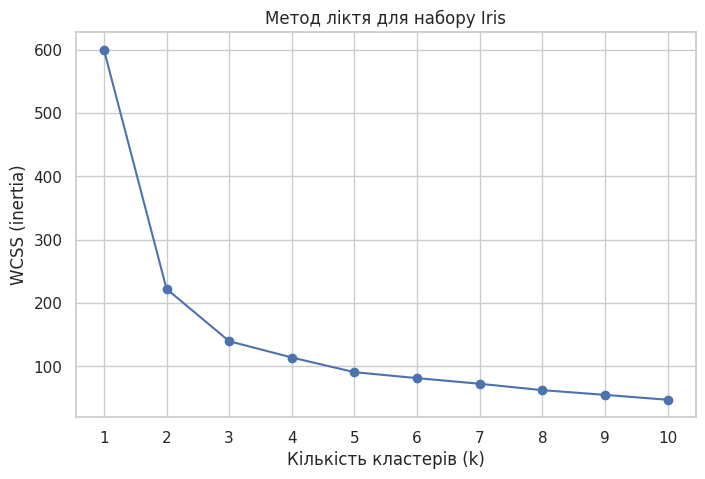

In [ ]:
# Стандартизуємо ознаки Iris
scaler_iris = StandardScaler()
iris_scaled = scaler_iris.fit_transform(iris_df)

# Метод ліктя: обчислюємо WCSS (inertia) для 1–10 кластерів
wcss_iris = []
k_values_iris = range(1, 11)

for k in k_values_iris:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    model.fit(iris_scaled)
    wcss_iris.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values_iris), wcss_iris, marker="o")
plt.title("Метод ліктя для набору Iris")
plt.xlabel("Кількість кластерів (k)")
plt.ylabel("WCSS (inertia)")
plt.xticks(list(k_values_iris))
plt.show()


**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

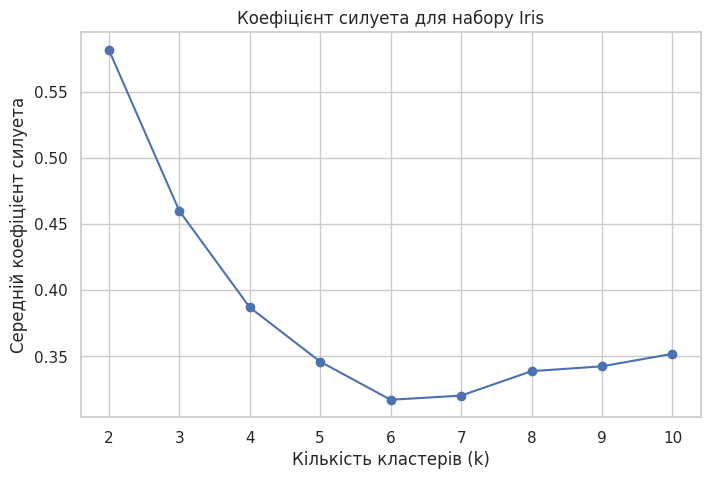

Найкраща кількість кластерів за коефіцієнтом силуета: 2


In [ ]:
silhouette_iris = {}
for k in range(2, 11):
    labels = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit_predict(iris_scaled)
    silhouette_iris[k] = silhouette_score(iris_scaled, labels)

plt.figure(figsize=(8, 5))
plt.plot(list(silhouette_iris.keys()), list(silhouette_iris.values()), marker="o")
plt.title("Коефіцієнт силуета для набору Iris")
plt.xlabel("Кількість кластерів (k)")
plt.ylabel("Середній коефіцієнт силуета")
plt.xticks(list(silhouette_iris.keys()))
plt.show()

best_k_iris_silhouette = max(silhouette_iris, key=silhouette_iris.get)
print("Найкраща кількість кластерів за коефіцієнтом силуета:", best_k_iris_silhouette)


**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

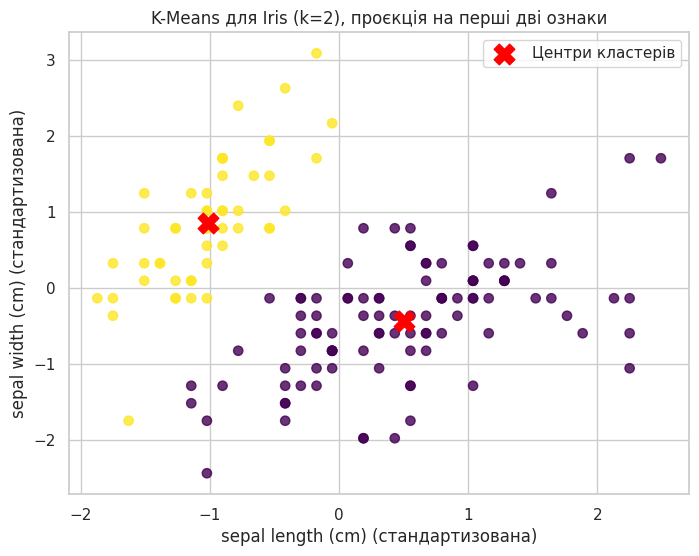

Розмірність даних для кластеризації: 3
Кількість об'єктів у кожному кластері: [100  50]
Коефіцієнт силуета для фінальної моделі: 0.5525


In [ ]:
# Фінальна кластеризація за трьома ознаками (для моделі беремо перші три)
iris_three = iris_df.iloc[:, :3]
scaler_iris_three = StandardScaler()
iris_three_scaled = scaler_iris_three.fit_transform(iris_three)

kmeans_iris_final = KMeans(n_clusters=2, random_state=RANDOM_STATE, n_init=10)
iris_clusters = kmeans_iris_final.fit_predict(iris_three_scaled)

# Відображаємо перші дві ознаки, хоча кластеризація виконана за трьома
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    iris_three_scaled[:, 0], iris_three_scaled[:, 1],
    c=iris_clusters, cmap="viridis", s=45, alpha=0.8
)
centers_2d = kmeans_iris_final.cluster_centers_[:, :2]
plt.scatter(centers_2d[:, 0], centers_2d[:, 1], c="red", marker="X", s=220,
            label="Центри кластерів")
plt.title("K-Means для Iris (k=2), проєкція на перші дві ознаки")
plt.xlabel(iris.feature_names[0] + " (стандартизована)")
plt.ylabel(iris.feature_names[1] + " (стандартизована)")
plt.legend()
plt.show()

print("Розмірність даних для кластеризації:", iris_three_scaled.shape[1])
print("Кількість об'єктів у кожному кластері:", np.bincount(iris_clusters))
print("Коефіцієнт силуета для фінальної моделі:",
      round(silhouette_score(iris_three_scaled, iris_clusters), 4))


**Короткий висновок до завдання 1:** порівняйте результати методу ліктя й методу силуетів. Поясніть, чому обрано два кластери та чи збігається такий вибір з отриманими графіками.

## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [ ]:
# Бібліотеки для аналізу, класифікації та кластеризації
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import glob
import subprocess
import sys

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42


**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [ ]:
# Завантаження набору даних із Kaggle через kagglehub
try:
    import kagglehub
except ImportError:
    %pip -q install kagglehub
    import kagglehub

path = kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")
print("Папка з набором даних:", path)

# Знаходимо CSV автоматично, щоб не залежати від пробілів у назві файлу
csv_files = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)
print("Знайдені CSV-файли:", csv_files)
if not csv_files:
    raise FileNotFoundError("У завантаженому наборі даних не знайдено CSV-файл.")
csv_path = next((f for f in csv_files if "student" in os.path.basename(f).lower()), csv_files[0])
print("Використовується файл:", csv_path)


Using Colab cache for faster access to the 'students-performance-dataset' dataset.
Папка з набором даних: /kaggle/input/students-performance-dataset
Знайдені CSV-файли: ['/kaggle/input/students-performance-dataset/Student_performance_data _.csv']
Використовується файл: /kaggle/input/students-performance-dataset/Student_performance_data _.csv


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [ ]:
df = pd.read_csv(csv_path)
display(df.head())
print("Розмір набору даних:", df.shape)


,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


Розмір набору даних: (2392, 15)


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [ ]:
print("Назви стовпців:")
print(df.columns.tolist())


Назви стовпців:
['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA', 'GradeClass']


**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [ ]:
print("Кількість пропущених значень у кожному стовпці:")
print(df.isnull().sum())
print("\\nЗагальна кількість пропусків:", int(df.isnull().sum().sum()))


Кількість пропущених значень у кожному стовпці:
StudentID            0
Age                  0
Gender               0
Ethnicity            0
ParentalEducation    0
StudyTimeWeekly      0
Absences             0
Tutoring             0
ParentalSupport      0
Extracurricular      0
Sports               0
Music                0
Volunteering         0
GPA                  0
GradeClass           0
dtype: int64
\nЗагальна кількість пропусків: 0


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [ ]:
print("Кількість повних дублікатів:", int(df.duplicated().sum()))


Кількість повних дублікатів: 0


**2.8. Описова статистика.** Виведіть основні описові статистики.

In [ ]:
display(df.describe(include="all").T)


,count,mean,std,min,25%,50%,75%,max
StudentID,2392.0,2196.500000,690.655244,1001.000000,1598.750000,2196.500000,2794.250000,3392.000000
Age,2392.0,16.468645,1.123798,15.000000,15.000000,16.000000,17.000000,18.000000
Gender,2392.0,0.510870,0.499986,0.000000,0.000000,1.000000,1.000000,1.000000
Ethnicity,2392.0,0.877508,1.028476,0.000000,0.000000,0.000000,2.000000,3.000000
ParentalEducation,2392.0,1.746237,1.000411,0.000000,1.000000,2.000000,2.000000,4.000000
StudyTimeWeekly,2392.0,9.771992,5.652774,0.001057,5.043079,9.705363,14.408410,19.978094
Absences,2392.0,14.541388,8.467417,0.000000,7.000000,15.000000,22.000000,29.000000
Tutoring,2392.0,0.301421,0.458971,0.000000,0.000000,0.000000,1.000000,1.000000
ParentalSupport,2392.0,2.122074,1.122813,0.000000,1.000000,2.000000,3.000000,4.000000
Extracurricular,2392.0,0.383361,0.486307,0.000000,0.000000,0.000000,1.000000,1.000000


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [ ]:
# Цільова змінна — GradeClass; StudentID не використовуємо як ознаку
required_columns = {"GradeClass", "StudentID"}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise KeyError(f"У наборі даних відсутні обов'язкові стовпці: {missing_columns}")

X = df.drop(columns=["GradeClass", "StudentID"]).copy()
y = df["GradeClass"].copy()

# Для цього набору ознаки мають бути числовими
X = X.apply(pd.to_numeric, errors="coerce")
X = X.fillna(X.median(numeric_only=True))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Розмір X_train:", X_train.shape)
print("Розмір X_test:", X_test.shape)
print("Кількість класів:", y.nunique())


Розмір X_train: (1913, 13)
Розмір X_test: (479, 13)
Кількість класів: 5


### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [ ]:
# Random Forest: підбір гіперпараметрів із 5-кратною крос-валідацією
rf = RandomForestClassifier(random_state=RANDOM_STATE, class_weight="balanced")
rf_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5]
}
rf_search = GridSearchCV(
    rf, rf_grid, cv=5, scoring="accuracy", n_jobs=-1, verbose=1
)
rf_search.fit(X_train, y_train)

rf_best = rf_search.best_estimator_
rf_pred = rf_best.predict(X_test)
rf_cv = rf_search.best_score_
rf_accuracy = accuracy_score(y_test, rf_pred)

print("Найкращі параметри Random Forest:", rf_search.best_params_)
print("Середня CV accuracy:", round(rf_cv, 4))
print("Тестова accuracy:", round(rf_accuracy, 4))


Fitting 5 folds for each of 12 candidates, totalling 60 fits
Найкращі параметри Random Forest: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
Середня CV accuracy: 0.9284
Тестова accuracy: 0.9228


### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [ ]:
# Logistic Regression: масштабовані ознаки та saga для багатокласової задачі
lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        solver="saga", max_iter=5000, random_state=RANDOM_STATE
    ))
])
lr_grid = {
    "model__C": [0.1, 1, 10],
    "model__penalty": ["l1", "l2"]
}
lr_search = GridSearchCV(
    lr_pipeline, lr_grid, cv=5, scoring="accuracy", n_jobs=-1, verbose=1
)
lr_search.fit(X_train, y_train)

lr_best = lr_search.best_estimator_
lr_pred = lr_best.predict(X_test)
lr_cv = lr_search.best_score_
lr_accuracy = accuracy_score(y_test, lr_pred)

print("Найкращі параметри Logistic Regression:", lr_search.best_params_)
print("Середня CV accuracy:", round(lr_cv, 4))
print("Тестова accuracy:", round(lr_accuracy, 4))


Fitting 5 folds for each of 6 candidates, totalling 30 fits
Найкращі параметри Logistic Regression: {'model__C': 0.1, 'model__penalty': 'l1'}
Середня CV accuracy: 0.8024
Тестова accuracy: 0.8184


### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [ ]:
# Support Vector Machine (SVM)
svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC())
])
svm_grid = {
    "model__C": [0.1, 1, 10],
    "model__kernel": ["linear", "rbf"],
    "model__gamma": ["scale", "auto"]
}
svm_search = GridSearchCV(
    svm_pipeline, svm_grid, cv=5, scoring="accuracy", n_jobs=-1, verbose=1
)
svm_search.fit(X_train, y_train)

svm_best = svm_search.best_estimator_
svm_pred = svm_best.predict(X_test)
svm_cv = svm_search.best_score_
svm_accuracy = accuracy_score(y_test, svm_pred)

print("Найкращі параметри SVM:", svm_search.best_params_)
print("Середня CV accuracy:", round(svm_cv, 4))
print("Тестова accuracy:", round(svm_accuracy, 4))


Fitting 5 folds for each of 12 candidates, totalling 60 fits
Найкращі параметри SVM: {'model__C': 10, 'model__gamma': 'scale', 'model__kernel': 'linear'}
Середня CV accuracy: 0.8521
Тестова accuracy: 0.858


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

In [ ]:
# Порівнюємо моделі за тестовою точністю та обираємо за CV accuracy
results = pd.DataFrame({
    "Модель": ["Random Forest", "Logistic Regression", "SVM"],
    "CV accuracy": [rf_cv, lr_cv, svm_cv],
    "Тестова accuracy": [rf_accuracy, lr_accuracy, svm_accuracy]
})
display(results.sort_values("CV accuracy", ascending=False).reset_index(drop=True))

best_model_name = results.loc[results["CV accuracy"].idxmax(), "Модель"]
best_predictions = {
    "Random Forest": rf_pred,
    "Logistic Regression": lr_pred,
    "SVM": svm_pred
}[best_model_name]

print("Найкраща модель за CV accuracy:", best_model_name)
print("\\nЗвіт класифікації для обраної моделі:")
print(classification_report(y_test, best_predictions, zero_division=0))


,Модель,CV accuracy,Тестова accuracy
0,Random Forest,0.928388,0.922756
1,SVM,0.852065,0.858038
2,Logistic Regression,0.802410,0.818372


Найкраща модель за CV accuracy: Random Forest
\nЗвіт класифікації для обраної моделі:
              precision    recall  f1-score   support

         0.0       1.00      0.48      0.65        21
         1.0       0.89      0.89      0.89        54
         2.0       0.91      0.95      0.93        78
         3.0       0.89      0.89      0.89        83
         4.0       0.94      0.97      0.96       243

    accuracy                           0.92       479
   macro avg       0.93      0.84      0.86       479
weighted avg       0.92      0.92      0.92       479



### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

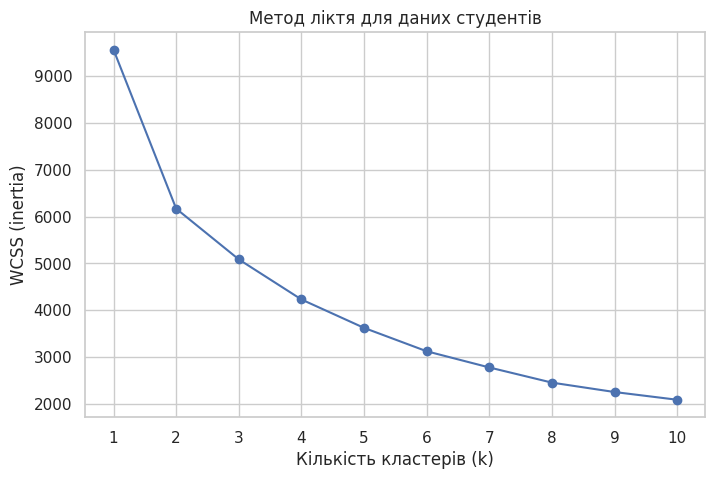

In [ ]:
# Кластеризація за чотирма числовими ознаками
cluster_features = ["Age", "StudyTimeWeekly", "Absences", "GPA"]
missing_features = set(cluster_features) - set(df.columns)
if missing_features:
    raise KeyError(f"Відсутні ознаки для кластеризації: {missing_features}")

student_cluster_df = df[cluster_features].apply(pd.to_numeric, errors="coerce")
student_cluster_df = student_cluster_df.fillna(student_cluster_df.median())
scaler_students = StandardScaler()
students_scaled = scaler_students.fit_transform(student_cluster_df)

wcss_students = []
k_students = range(1, 11)
for k in k_students:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    km.fit(students_scaled)
    wcss_students.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_students), wcss_students, marker="o")
plt.title("Метод ліктя для даних студентів")
plt.xlabel("Кількість кластерів (k)")
plt.ylabel("WCSS (inertia)")
plt.xticks(list(k_students))
plt.show()


### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

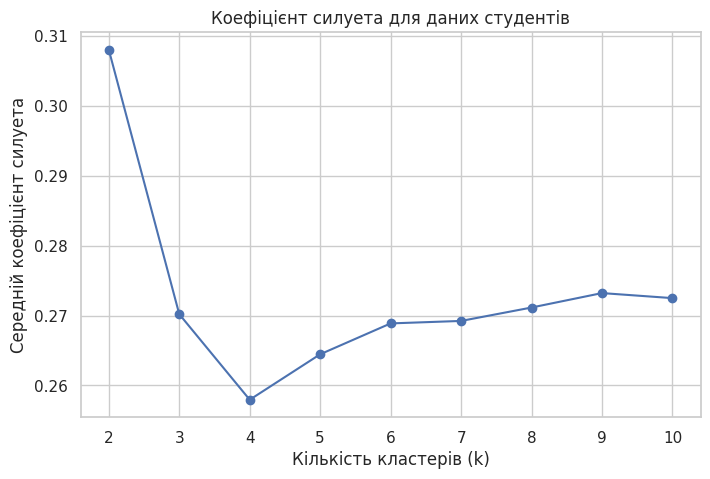

Найкраща кількість кластерів за силуетом: 2


In [ ]:
silhouette_students = {}
for k in range(2, 11):
    labels = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit_predict(students_scaled)
    silhouette_students[k] = silhouette_score(students_scaled, labels)

plt.figure(figsize=(8, 5))
plt.plot(list(silhouette_students.keys()), list(silhouette_students.values()), marker="o")
plt.title("Коефіцієнт силуета для даних студентів")
plt.xlabel("Кількість кластерів (k)")
plt.ylabel("Середній коефіцієнт силуета")
plt.xticks(list(silhouette_students.keys()))
plt.show()

best_k_students_silhouette = max(silhouette_students, key=silhouette_students.get)
print("Найкраща кількість кластерів за силуетом:", best_k_students_silhouette)


### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [ ]:
%pip -q install kneed yellowbrick


**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from kneed import KneeLocator
from yellowbrick.cluster import KElbowVisualizer


**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [ ]:
# Для PCA використовуємо всі ознаки, крім ідентифікатора та цільового класу
X_pca = df.drop(columns=["StudentID", "GradeClass"]).copy()
X_pca = X_pca.apply(pd.to_numeric, errors="coerce")
X_pca = X_pca.fillna(X_pca.median(numeric_only=True))

scaler_pca = StandardScaler()
X_pca_scaled = scaler_pca.fit_transform(X_pca)

print("Кількість початкових ознак для PCA:", X_pca_scaled.shape[1])


Кількість початкових ознак для PCA: 13


**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [ ]:
pca_full = PCA()
pca_full.fit(X_pca_scaled)

explained_variance = pca_full.explained_variance_ratio_
print("Частка поясненої дисперсії кожної компоненти:")
for i, value in enumerate(explained_variance, start=1):
    print(f"Компонента {i}: {value:.4f} ({value*100:.2f}%)")


Частка поясненої дисперсії кожної компоненти:
Компонента 1: 0.1525 (15.25%)
Компонента 2: 0.0861 (8.61%)
Компонента 3: 0.0827 (8.27%)
Компонента 4: 0.0807 (8.07%)
Компонента 5: 0.0786 (7.86%)
Компонента 6: 0.0779 (7.79%)
Компонента 7: 0.0763 (7.63%)
Компонента 8: 0.0760 (7.60%)
Компонента 9: 0.0744 (7.44%)
Компонента 10: 0.0738 (7.38%)
Компонента 11: 0.0717 (7.17%)
Компонента 12: 0.0675 (6.75%)
Компонента 13: 0.0018 (0.18%)


**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

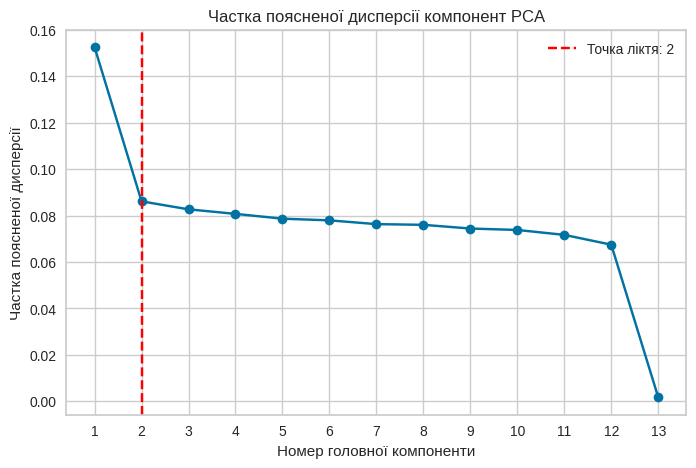

Кількість компонент за KneeLocator/резервним правилом: 2


In [ ]:
# Шукаємо точку перегину у спаданні часток поясненої дисперсії
component_numbers = np.arange(1, len(explained_variance) + 1)
knee_locator = KneeLocator(
    component_numbers, explained_variance,
    curve="convex", direction="decreasing"
)
knee_components = knee_locator.knee

plt.figure(figsize=(8, 5))
plt.plot(component_numbers, explained_variance, marker="o")
if knee_components is not None:
    plt.axvline(knee_components, color="red", linestyle="--",
                label=f"Точка ліктя: {knee_components}")
    plt.legend()
plt.title("Частка поясненої дисперсії компонент PCA")
plt.xlabel("Номер головної компоненти")
plt.ylabel("Частка поясненої дисперсії")
plt.xticks(component_numbers)
plt.show()

if knee_components is None:
    knee_components = int(np.argmax(np.cumsum(explained_variance) >= 0.80) + 1)
    print("Точку ліктя автоматично не знайдено; використано мінімальну кількість компонент для 80% дисперсії.")
print("Кількість компонент за KneeLocator/резервним правилом:", knee_components)


**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

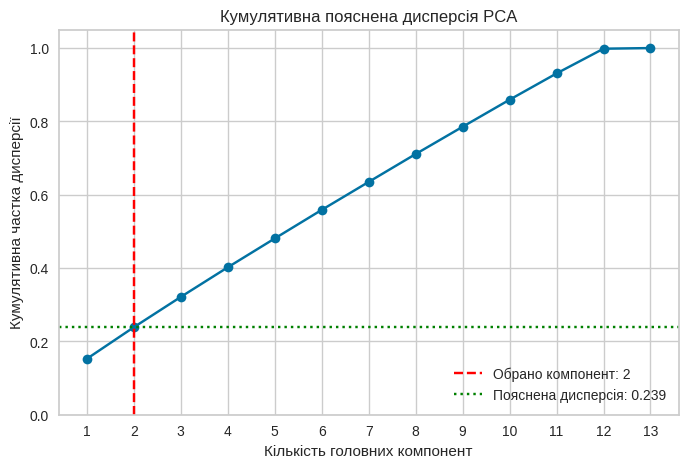

Обрано головних компонент: 2
Фактична кумулятивна частка поясненої дисперсії: 0.2386 (23.86%)
Розмір даних після PCA: (2392, 2)


In [ ]:
# Кумулятивна пояснена дисперсія та перетворення PCA
cumulative_variance = np.cumsum(explained_variance)
selected_components = int(knee_components)
selected_variance = cumulative_variance[selected_components - 1]

plt.figure(figsize=(8, 5))
plt.plot(component_numbers, cumulative_variance, marker="o")
plt.axvline(selected_components, color="red", linestyle="--",
            label=f"Обрано компонент: {selected_components}")
plt.axhline(selected_variance, color="green", linestyle=":",
            label=f"Пояснена дисперсія: {selected_variance:.3f}")
plt.title("Кумулятивна пояснена дисперсія PCA")
plt.xlabel("Кількість головних компонент")
plt.ylabel("Кумулятивна частка дисперсії")
plt.xticks(component_numbers)
plt.ylim(0, 1.05)
plt.legend()
plt.show()

pca = PCA(n_components=selected_components)
X_pca_transformed = pca.fit_transform(X_pca_scaled)

print("Обрано головних компонент:", selected_components)
print("Фактична кумулятивна частка поясненої дисперсії:",
      round(selected_variance, 4), f"({selected_variance*100:.2f}%)")
print("Розмір даних після PCA:", X_pca_transformed.shape)


Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [ ]:
from yellowbrick.cluster import KElbowVisualizer


**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

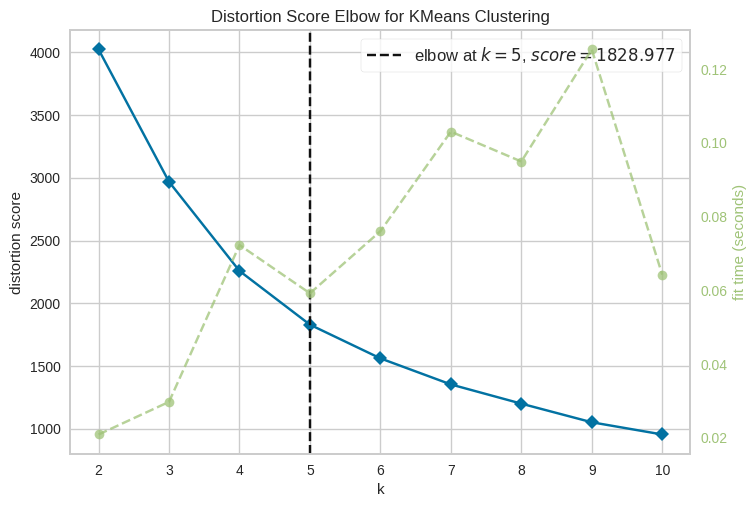

Оптимальна кількість кластерів за KElbowVisualizer: 5


In [ ]:
# Метод ліктя для даних після PCA
pca_kmeans = KMeans(random_state=RANDOM_STATE, n_init=10)
visualizer = KElbowVisualizer(pca_kmeans, k=(2, 11), metric="distortion")
visualizer.fit(X_pca_transformed)
visualizer.show()

print("Оптимальна кількість кластерів за KElbowVisualizer:", visualizer.elbow_value_)


## Висновки

Порівняйте результати різних способів визначення кількості кластерів та сформулюйте короткі висновки. Для завдання 2 окремо поясніть різницю між класифікацією за `GradeClass` і кластеризацією без цільової змінної. Зазначте, скільки головних компонент обрано та яку частку дисперсії вони пояснюють.

In [ ]:
print("ВИСНОВКИ")
print("1. Для Iris метод ліктя оцінюється за графіком WCSS, а метод силуета — за максимальним середнім коефіцієнтом.")
print(f"   Найкращий результат силуета для Iris: k={best_k_iris_silhouette}.")
print("2. У фінальній моделі Iris використано 2 кластери, як зазначено в умові.")
print("3. Для студентських даних класифікація прогнозує GradeClass за відомими прикладами,")
print("   тоді як кластеризація групує об'єкти без використання GradeClass.")
print(f"4. Найкраща класифікаційна модель за CV accuracy: {best_model_name}.")
print(f"5. За методом силуета для студентських даних найкраще k={best_k_students_silhouette}.")
print(f"6. Для PCA обрано {selected_components} компонент(и), що пояснюють {selected_variance*100:.2f}% дисперсії.")
if 'elbow_value_' in dir(visualizer):
    print(f"7. KElbowVisualizer після PCA визначив k={visualizer.elbow_value_}.")


ВИСНОВКИ
1. Для Iris метод ліктя оцінюється за графіком WCSS, а метод силуета — за максимальним середнім коефіцієнтом.
   Найкращий результат силуета для Iris: k=2.
2. У фінальній моделі Iris використано 2 кластери, як зазначено в умові.
3. Для студентських даних класифікація прогнозує GradeClass за відомими прикладами,
   тоді як кластеризація групує об'єкти без використання GradeClass.
4. Найкраща класифікаційна модель за CV accuracy: Random Forest.
5. За методом силуета для студентських даних найкраще k=2.
6. Для PCA обрано 2 компонент(и), що пояснюють 23.86% дисперсії.
7. KElbowVisualizer після PCA визначив k=5.
